In [1]:
# %%
# Aggregation plateau test
# Purpose: find the scale at which the 1km RF prediction's spatial structure
# is exhausted, by computing Pearson r between the original 1km field and
# block-averaged versions at progressively coarser resolutions.
#
# Method per month:
#   1. Load 1km RF predicted raster.
#   2. For each target resolution in AGG_RESOLUTIONS:
#        a. Block-average 1km → coarse  (Resampling.average = pixel mean).
#        b. Upsample coarse → 1km grid  (Resampling.nearest = each fine pixel
#           inherits its containing coarse block's mean value).
#        c. Pearson r between the upsampled field and the original 1km field.
#   3. The scale where r plateaus near 1.0 is the internal complexity floor.
#      Below that scale, the prediction adds no new spatial structure.
#
# Outputs
#   plateau_monthly.csv   — r per (month × agg_resolution)
#   plateau_seasonal.csv  — median r ± IQR per (season × agg_resolution)
#   plateau_curve.png     — main plot

# %%
import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rioxarray as rxr
from rasterio.enums import Resampling
from scipy.stats import pearsonr
from tqdm import tqdm

# ── CONFIGURATION ─────────────────────────────────────────────────────────────

START_YEAR, START_MONTH = 2001, 1
END_YEAR,   END_MONTH   = 2005, 12

# Resolutions to aggregate TO (must have a corresponding template raster)
AGG_RESOLUTIONS = [1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6]

OUT_ROOT    = r"..\Data\Processed\Resolution_Skill_Test"
PLATEAU_OUT = r"..\Data\Processed\Aggregation_Plateau_Test"
os.makedirs(PLATEAU_OUT, exist_ok=True)

TEMPLATE_PATHS = {
    1:   r"..\Data\Datasets\TemplateRasters\template_raster_WGS_1km.tif",
    1.5: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_1_5km.tif",
    2:   r"..\Data\Datasets\TemplateRasters\template_raster_WGS_2km.tif",
    2.5: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_2_5km.tif",
    3:   r"..\Data\Datasets\TemplateRasters\template_raster_WGS_3km.tif",
    3.5: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_3_5km.tif",
    4:   r"..\Data\Datasets\TemplateRasters\template_raster_WGS_4km.tif",
    4.5: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_4_5km.tif",
    5:   r"..\Data\Datasets\TemplateRasters\template_raster_WGS_5km.tif",
    5.5: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_5_5km.tif",
    6:   r"..\Data\Datasets\TemplateRasters\template_raster_WGS_6km.tif",
}

SEASONS = {
    "monsoon":      [6, 7, 8, 9],
    "post_monsoon": [10, 11],
    "winter":       [12, 1, 2],
    "pre_monsoon":  [3, 4, 5],
}
SEASON_ORDER  = ["monsoon", "post_monsoon", "winter", "pre_monsoon"]
SEASON_LABELS = {
    "monsoon":      "Monsoon (JJAS)",
    "post_monsoon": "Post-Monsoon (ON)",
    "winter":       "Winter (DJF)",
    "pre_monsoon":  "Pre-Monsoon (MAM)",
}
SEASON_COLORS = {
    "monsoon":      "#1f77b4",
    "post_monsoon": "#ff7f0e",
    "winter":       "#2ca02c",
    "pre_monsoon":  "#d62728",
}

month_range = pd.period_range(
    start=f"{START_YEAR}-{START_MONTH:02d}",
    end=f"{END_YEAR}-{END_MONTH:02d}",
    freq="M",
)


def mlabel(year, month):
    return f"{year}{month:02d}"


def season_of(month):
    for s, months in SEASONS.items():
        if month in months:
            return s
    return "unknown"


In [2]:
# %%
# ── PRE-LOAD TEMPLATES (lazy — just grid metadata, low memory) ────────────────

template_1km = rxr.open_rasterio(TEMPLATE_PATHS[1], masked=True)

coarse_templates = {}
for res in AGG_RESOLUTIONS:
    tp = TEMPLATE_PATHS.get(res, "")
    if os.path.exists(tp):
        coarse_templates[res] = rxr.open_rasterio(tp, masked=True)
    else:
        print(f"  WARNING: template not found for {res}km — will skip this resolution")

print(f"  Template resolutions available: {sorted(coarse_templates.keys())}")

  Template resolutions available: [1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6]


In [3]:

# %%
# ── MAIN LOOP ─────────────────────────────────────────────────────────────────

rows = []

for period in tqdm(month_range, desc="Months"):
    year, month = period.year, period.month

    path_1km = os.path.join(
        OUT_ROOT, "1km", "Predicted_Rasters",
        f"pred_monthly_{mlabel(year, month)}.tif",
    )
    if not os.path.exists(path_1km):
        tqdm.write(f"  [{mlabel(year, month)}] 1km raster not found — skipping")
        continue

    # Load and align 1km prediction to the 1km template grid
    da_1km = rxr.open_rasterio(path_1km, masked=True)
    if "band" in da_1km.dims:
        da_1km = da_1km.squeeze("band", drop=True)
    da_1km = da_1km.rio.reproject_match(template_1km, resampling=Resampling.nearest)
    da_1km = da_1km.load()

    vals_1km = da_1km.values.ravel().astype(np.float64)

    for res, template_coarse in coarse_templates.items():
        try:
            # Step 1 — block-average 1km → coarse (Resampling.average = pixel mean)
            da_coarse = da_1km.rio.reproject_match(
                template_coarse, resampling=Resampling.average
            )

            # Step 2 — upsample coarse → 1km via nearest neighbour
            # Result: every fine pixel takes the mean value of its containing coarse block
            da_up = da_coarse.rio.reproject_match(
                template_1km, resampling=Resampling.nearest
            )

            # Step 3 — Pearson r over pixels valid in both fields
            vals_up = da_up.values.ravel().astype(np.float64)
            valid   = np.isfinite(vals_1km) & np.isfinite(vals_up)

            if valid.sum() < 100:
                tqdm.write(f"  [{mlabel(year, month)}] [{res}km] too few valid pixels")
                continue

            r, _ = pearsonr(vals_1km[valid], vals_up[valid])

            rows.append({
                "year":       year,
                "month":      month,
                "season":     season_of(month),
                "agg_res_km": res,
                "pearson_r":  round(float(r), 6),
                "n_pixels":   int(valid.sum()),
            })

            da_coarse.close()
            da_up.close()
            del da_coarse, da_up
            gc.collect()

        except Exception as exc:
            tqdm.write(f"  [{mlabel(year, month)}] [{res}km] error: {exc}")

    da_1km.close()
    del da_1km, vals_1km
    gc.collect()

# Close templates
for da in coarse_templates.values():
    da.close()
template_1km.close()

Months: 100%|██████████| 60/60 [01:09<00:00,  1.15s/it]


In [4]:
# %%
# ── SAVE AND SUMMARISE ────────────────────────────────────────────────────────

df = pd.DataFrame(rows)
monthly_csv = os.path.join(PLATEAU_OUT, "plateau_monthly.csv")
df.to_csv(monthly_csv, index=False)
print(f"\n  Monthly results: {len(df)} rows → {monthly_csv}")

# Seasonal summary: median ± IQR per agg_resolution × season
df_seas = (
    df.groupby(["agg_res_km", "season"])["pearson_r"]
    .agg(
        median = "median",
        q25    = lambda x: x.quantile(0.25),
        q75    = lambda x: x.quantile(0.75),
        n      = "count",
    )
    .reset_index()
)
seasonal_csv = os.path.join(PLATEAU_OUT, "plateau_seasonal.csv")
df_seas.to_csv(seasonal_csv, index=False)

# Print pivot
pivot = df_seas.pivot(index="agg_res_km", columns="season", values="median")
pivot = pivot[[s for s in SEASON_ORDER if s in pivot.columns]]
print("\n  Median Pearson r (aggregated field vs original 1 km field):")
print("  " + "─" * 60)
print(pivot.round(4).to_string())

# Check: at what resolution does r first exceed 0.99 / 0.95 per season?
print("\n  Complexity floor (first resolution where median r ≥ threshold):")
for threshold, label in [(0.99, "r ≥ 0.99"), (0.95, "r ≥ 0.95")]:
    floors = {}
    for season in SEASON_ORDER:
        sub = df_seas[df_seas["season"] == season].sort_values("agg_res_km")
        crossed = sub.loc[sub["median"] >= threshold, "agg_res_km"]
        floors[season] = f"{crossed.iloc[0]} km" if not crossed.empty else "> 6 km"
    print(f"  {label}: {floors}")



  Monthly results: 600 rows → ..\Data\Processed\Aggregation_Plateau_Test\plateau_monthly.csv

  Median Pearson r (aggregated field vs original 1 km field):
  ────────────────────────────────────────────────────────────
season      monsoon  post_monsoon  winter  pre_monsoon
agg_res_km                                            
1.5          0.9980        0.9911  0.9950       0.9974
2.0          0.9971        0.9873  0.9930       0.9963
2.5          0.9966        0.9847  0.9916       0.9955
3.0          0.9960        0.9818  0.9900       0.9946
3.5          0.9952        0.9794  0.9887       0.9939
4.0          0.9947        0.9766  0.9874       0.9930
4.5          0.9941        0.9750  0.9863       0.9924
5.0          0.9936        0.9730  0.9853       0.9918
5.5          0.9931        0.9709  0.9844       0.9910
6.0          0.9926        0.9695  0.9834       0.9905

  Complexity floor (first resolution where median r ≥ threshold):
  r ≥ 0.99: {'monsoon': '1.5 km', 'post_monsoon': '1.

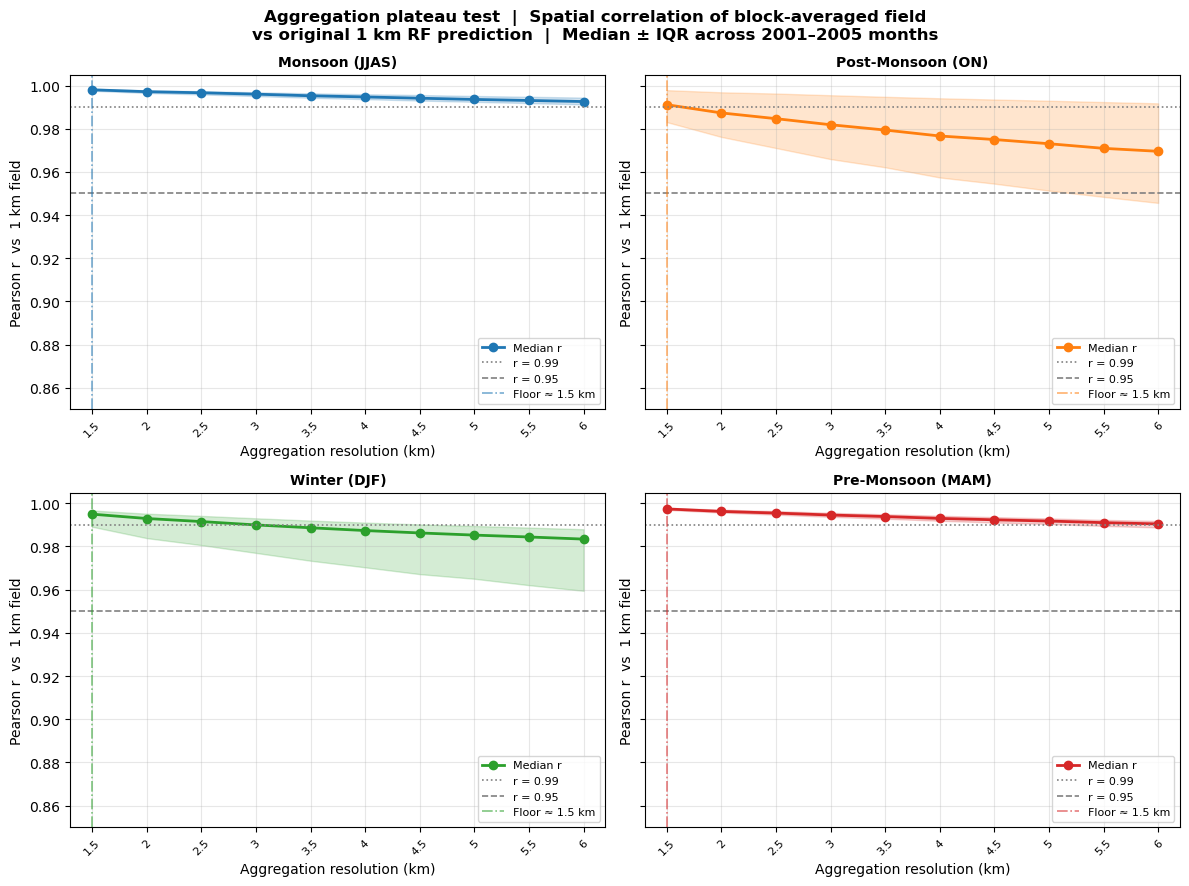


  Plot saved → ..\Data\Processed\Aggregation_Plateau_Test\plateau_curve.png
  All outputs → ..\Data\Processed\Aggregation_Plateau_Test


In [5]:
# %%
# ── PLOT ──────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True)
axes = axes.ravel()

for ax, season in zip(axes, SEASON_ORDER):
    sub = df_seas[df_seas["season"] == season].sort_values("agg_res_km")
    if sub.empty:
        ax.set_visible(False)
        continue

    c = SEASON_COLORS[season]

    # IQR band
    ax.fill_between(sub["agg_res_km"], sub["q25"], sub["q75"],
                    alpha=0.20, color=c)
    # Median curve
    ax.plot(sub["agg_res_km"], sub["median"],
            "o-", color=c, lw=2, ms=6, label="Median r")

    # Reference thresholds
    ax.axhline(0.99, color="gray", ls=":", lw=1.2, label="r = 0.99")
    ax.axhline(0.95, color="gray", ls="--", lw=1.2, label="r = 0.95")

    # Annotate the 0.99 crossing if it falls within the plot range
    crossed = sub.loc[sub["median"] >= 0.99, "agg_res_km"]
    if not crossed.empty:
        floor_res = float(crossed.iloc[0])
        ax.axvline(floor_res, color=c, ls="-.", lw=1.2, alpha=0.6,
                   label=f"Floor ≈ {floor_res} km")

    ax.set_title(SEASON_LABELS[season], fontsize=10, fontweight="bold")
    ax.set_xlabel("Aggregation resolution (km)")
    ax.set_ylabel("Pearson r  vs  1 km field")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(AGG_RESOLUTIONS[0] - 0.2, AGG_RESOLUTIONS[-1] + 0.2)
    ax.set_xticks(AGG_RESOLUTIONS)
    ax.set_xticklabels([str(r) for r in AGG_RESOLUTIONS], rotation=45, fontsize=8)
    ax.set_ylim(0.85, 1.005)   # adjust lower bound if r drops below 0.85

fig.suptitle(
    "Aggregation plateau test  |  Spatial correlation of block-averaged field\n"
    "vs original 1 km RF prediction  |  Median ± IQR across 2001–2005 months",
    fontsize=12, fontweight="bold",
)
plt.tight_layout()
plot_path = os.path.join(PLATEAU_OUT, "plateau_curve.png")
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"\n  Plot saved → {plot_path}")
print(f"  All outputs → {PLATEAU_OUT}")